# [DEVICE]   01 - High-Wavenumber (HW) Raman Map & Metadata Inspector

This notebook inspects individual **High-Wavenumber (HW)** Raman map files (`.h5`) from the pre-training data lake (`spectrabreast_hw`, `pdo_hw_maps`, `riverd_meat_hw`).

### Key Features:
1. **Dynamic Metadata Extraction**: Walks through the entire HDF5 hierarchy with an iterative loop to extract **every single attribute, metadata field, and clinical label** (`Tumoral tissue` vs `Healty tissue`, `IDC`, ICD-10 `C50.9`, laser wavelength, exposure time, clinical trial NCT, etc.).
2. **Understanding the 2D Raman Map**: Explains what a 2D spatial map is and how it maps chemical intensity to tissue morphology.
3. **Single Pixel Spectra across Full HW**: Visualizes individual spectra across the **entire acquired High-Wavenumber range** (~2480 to 3300/4000 cm⁻¹), highlighting the C-H stretch region (2800–3050 cm⁻¹) and O-H/water region.
4. **Multi-Spectra Overlay, Mean & Variance**: Analyzes intra-map spectral variability with mean spectrum, shaded standard deviation, and spectral variance ($\sigma^2$).
5. **Organized Exports**: Automatically saves generated diagnostic figures to `outputs/figures/`.

In [19]:
# 1. Standard library imports
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Matplotlib configuration
plt.style.use('default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

print('[OK] Libraries imported successfully.')

[OK] Libraries imported successfully.


## 2. Select the High-Wavenumber Map File
Specify the filename or partial name of the `.h5` file you want to inspect. The notebook will automatically search inside `data/00_raw/pretrain/HW/`.

In [20]:
# ==============================================================================
# SPECIFY THE MAP FILE TO INSPECT
# ==============================================================================
# Examples from spectrabreast_hw (Breast tissue patient maps, 785 nm):
# - 'SB003HT _map_ 785_3sec1_50Lx_CH_01.h5'   (Healthy tissue)
# - 'SB003TT 2.2 _map_ 785_3sec1_50Lx_CH_01.h5' (Tumoral tissue, IDC)
# - 'SB004HT _map_ 785_3sec1_50Lx_CH_01.h5'   (Healthy tissue)
# - 'SB004TT 2 _map_ 785_3sec1_50Lx_CH_01.h5' (Tumoral tissue, IDC)
# Examples from pdo_hw_maps (High-definition Organoids, 532 nm):
# - 'CMA64  map hd 532 CH confocal PDO2.h5'
# Examples from riverd_meat_hw (Reference tissue, 671 nm):
# - 'rxh1.h5'

FILE_NAME = 'SB003HT _map_ 785_3sec1_50Lx_CH_01.h5'

# Locate file in data/00_raw/pretrain/HW
hw_root = Path('../data/00_raw/pretrain/HW').resolve()
if not hw_root.exists():
    hw_root = Path('data/00_raw/pretrain/HW').resolve()

matched_files = list(hw_root.rglob(f'*{FILE_NAME}*'))
if not matched_files:
    matched_files = [f for f in hw_root.rglob('*.h5') if FILE_NAME.lower() in f.name.lower()]

if matched_files:
    map_filepath = matched_files[0]
    print(f'[OK] Target File: {map_filepath.name}')
    print(f'     Dataset:     {map_filepath.parent.name}')
    print(f'     File Size:   {map_filepath.stat().st_size / (1024*1024):.2f} MB')
else:
    raise FileNotFoundError(f'File "{FILE_NAME}" was not found in {hw_root}')

[OK] Target File: SB003HT _map_ 785_3sec1_50Lx_CH_01.h5
     Dataset:     spectrabreast_hw
     File Size:   11.57 MB


## 3. Comprehensive Metadata & Label Extraction via Dynamic Loop
Instead of hardcoding a few keys, we iterate through the **entire HDF5 hierarchy** to discover all groups, datasets, attributes, clinical labels, and hardware parameters.

In [21]:
# Function to recursively iterate through all HDF5 nodes and extract all metadata
def extract_all_h5_metadata(filepath: Path) -> pd.DataFrame:
    records = []
    
    with h5py.File(filepath, 'r') as h5:
        # 1. Iterate over root-level attributes
        for attr_key, attr_val in h5.attrs.items():
            records.append({
                'Path': '/',
                'Category': 'Root Attribute',
                'Field': attr_key,
                'Value': str(attr_val)
            })
        
        # 2. Walk through every group and dataset in the hierarchy
        def node_visitor(name, obj):
            # Record any attributes on this group or dataset
            for ak, av in obj.attrs.items():
                records.append({
                    'Path': f'/{name}',
                    'Category': 'Attribute',
                    'Field': ak,
                    'Value': str(av)
                })
            
            # If dataset, record its scalar value or array shape info
            if isinstance(obj, h5py.Dataset):
                if obj.size == 1:
                    val = obj[()]
                    if isinstance(val, bytes):
                        val = val.decode('utf-8', errors='ignore').strip()
                    elif isinstance(val, np.ndarray):
                        val = val.item()
                    val_str = str(val).strip()
                    if val_str and val_str.lower() != 'nan':
                        records.append({
                            'Path': f'/{name}',
                            'Category': 'Dataset Value',
                            'Field': name.split('/')[-1],
                            'Value': val_str
                        })
                elif obj.size <= 5:
                    records.append({
                        'Path': f'/{name}',
                        'Category': 'Dataset Value',
                        'Field': name.split('/')[-1],
                        'Value': str(obj[:].tolist())
                    })
                else:
                    records.append({
                        'Path': f'/{name}',
                        'Category': 'Array Info',
                        'Field': name.split('/')[-1],
                        'Value': f'shape={obj.shape}, dtype={obj.dtype}'
                    })
                    
        h5.visititems(node_visitor)
        
    df_meta = pd.DataFrame(records)
    return df_meta

# Run dynamic loop extraction
df_all_metadata = extract_all_h5_metadata(map_filepath)
print(f'[OK] Discovered {len(df_all_metadata)} total metadata items and attributes.')

# Extract key variables for spectral inspection
with h5py.File(map_filepath, 'r') as h5:
    data_grp = h5['ENTRY/data']
    raman_shift = np.array(data_grp['raman_shift']).flatten()
    raw_intensity = np.array(data_grp['intensity'], dtype=np.float64)
    
    # Grid dimensions from attributes
    ny = int(data_grp.attrs.get('ny', raw_intensity.shape[0] if raw_intensity.ndim >= 2 else 1))
    nx = int(data_grp.attrs.get('nx', raw_intensity.shape[1] if raw_intensity.ndim >= 3 else 1))
    n_spectra = int(data_grp.attrs.get('spectral_count', ny * nx))
    spatial_units = str(data_grp.attrs.get('coordinate_units', 'micrometers'))
    if isinstance(spatial_units, bytes): spatial_units = spatial_units.decode()

    # Spatial coordinates if available
    x_coords = np.array(data_grp['x']).flatten() if 'x' in data_grp else np.arange(nx, dtype=np.float64)
    y_coords = np.array(data_grp['y']).flatten() if 'y' in data_grp else np.arange(ny, dtype=np.float64)

    # Reshape intensity to 3D cube: (Ny, Nx, Wavenumbers)
    n_wn = len(raman_shift)
    if raw_intensity.ndim == 3:
        intensity_cube = raw_intensity
    elif raw_intensity.ndim == 2:
        intensity_cube = raw_intensity.reshape(ny, nx, n_wn) if raw_intensity.shape == (ny*nx, n_wn) else raw_intensity.reshape(ny, nx, -1)
    else:
        intensity_cube = raw_intensity.reshape(ny, nx, n_wn)

    # Check for auxiliary microscope white-light photo
    has_optical_photo = 'ENTRY/auxiliary/white_light/image' in h5
    optical_photo = h5['ENTRY/auxiliary/white_light/image'][:] if has_optical_photo else None

    # Helper function for scalar lookups
    def get_meta(path, default='N/A'):
        if path in h5:
            v = h5[path][()]
            if isinstance(v, bytes): v = v.decode('utf-8', errors='ignore')
            v_str = str(v).strip()
            return v_str if v_str and v_str.lower() != 'nan' else default
        return default

    tissue_label = get_meta('SAMPLE/SAMPLE_INFO/sample_notes')
    histology = get_meta('SAMPLE/SAMPLE_DONOR/diagnosis_notes')
    icd10_code = get_meta('SAMPLE/SAMPLE_DONOR/diagnosis_code')
    donor_id = get_meta('SAMPLE/SAMPLE_DONOR/donor_id')
    sample_id = get_meta('SAMPLE/sample_id')
    sample_type = get_meta('SAMPLE/SAMPLE_INFO/detailed_sample_type')
    provenance = get_meta('SAMPLE/SAMPLE_INFO/sample_provenance')
    clinical_trial = get_meta('PROJECT/governance_reference')
    laser_nm = get_meta('ENTRY/instrument/laser/wavelength')
    laser_filter = get_meta('ENTRY/instrument/laser/filter')
    exposure_time = get_meta('ENTRY/measurement/exposure_time')
    substrate = get_meta('ENTRY/measurement/substrate')
    instrument = get_meta('ENTRY/instrument/name')

# Display Structured Summary
print('=' * 75)
print(f'STRUCTURED METADATA & LABELS: {map_filepath.name}')
print('=' * 75)
print(f'[LABEL]     BIOLOGICAL LABEL:      >>> {tissue_label.upper()} <<<')
print(f'[CLINICAL] HISTOLOGY / DIAGNOSIS: {histology} (ICD-10 Code: {icd10_code})')
print(f'[SAMPLE]   SAMPLE TYPE:           {sample_type} (Donor: {donor_id}, Sample: {sample_id})')
print(f'[CLINICAL] CLINICAL TRIAL / SITE: {clinical_trial} | Center: {provenance}')
print('-' * 75)
print(f'[DEVICE]   INSTRUMENT:            {instrument}')
print(f'[LASER]    LASER WAVELENGTH:      {laser_nm} nm (ND Filter: {laser_filter})')
print(f'[EXPOSURE] EXPOSURE TIME:         {exposure_time} s | Substrate: {substrate}')
print(f'[GRID]     SPATIAL GRID (Ny x Nx):{ny} rows x {nx} columns = {n_spectra:,} total spectra')
print(f'[RANGE]    FULL HW RANGE:         {raman_shift.min():.1f} - {raman_shift.max():.1f} cm^-1 ({n_wn} spectral channels)')
print(f'[OPTICAL]  OPTICAL PHOTO IN H5:   {"YES (White Light RGB)" if has_optical_photo else "No"}')
print('=' * 75)

# Show sample of all discovered metadata items
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
print(f'\n[OK] Displaying ALL {len(df_all_metadata)} discovered metadata items and attributes:')
display(df_all_metadata)

[OK] Discovered 97 total metadata items and attributes.
STRUCTURED METADATA & LABELS: SB003HT _map_ 785_3sec1_50Lx_CH_01.h5
[LABEL]     BIOLOGICAL LABEL:      >>> HEALTY TISSUE <<<
[CLINICAL] HISTOLOGY / DIAGNOSIS: IDC (ICD-10 Code: C50.9)
[SAMPLE]   SAMPLE TYPE:           OCT Tissue slice (Donor: SB003, Sample: SB003HT)
[CLINICAL] CLINICAL TRIAL / SITE: NCT07111728 | Center: ICS Maugeri
---------------------------------------------------------------------------
[DEVICE]   INSTRUMENT:            Renishaw inVia
[LASER]    LASER WAVELENGTH:      785 nm (ND Filter: 100%)
[EXPOSURE] EXPOSURE TIME:         2 s | Substrate: CaF2
[GRID]     SPATIAL GRID (Ny x Nx):32 rows x 82 columns = 2,624 total spectra
[RANGE]    FULL HW RANGE:         2489.0 - 3258.9 cm^-1 (1015 spectral channels)
[OPTICAL]  OPTICAL PHOTO IN H5:   YES (White Light RGB)

[OK] Displaying ALL 97 discovered metadata items and attributes:


,Path,Category,Field,Value
0,/,Root Attribute,fairaman_version,1.3
1,/,Root Attribute,source_format,wdf
2,/ENTRY,Attribute,NX_class,NXentry
3,/ENTRY,Attribute,definition,NXraman
4,/ENTRY/auxiliary,Attribute,NX_class,NXcollection
5,/ENTRY/auxiliary/acquisition_map,Attribute,NX_class,NXdata
6,/ENTRY/auxiliary/acquisition_map,Attribute,signal,image
7,/ENTRY/auxiliary/acquisition_map/image,Attribute,CLASS,IMAGE
8,/ENTRY/auxiliary/acquisition_map/image,Attribute,IMAGE_SUBCLASS,IMAGE_TRUECOLOR
9,/ENTRY/auxiliary/acquisition_map/image,Attribute,IMAGE_VERSION,1.2


## 4. What is a 2D Raman Map and Why is it Useful?

### [INFO]     Intuitive Explanation:
- In point Raman spectroscopy, you measure just a single point on a glass slide.
- In **Raman Mapping**, a biological tissue slice is placed on a motorized microscope stage. The laser moves point-by-point in a regular rectangular grid of $Ny$ rows by $Nx$ columns (e.g. $32 \times 82 = 2,624$ points).
- At **every single point $(x, y)$**, a complete Raman spectrum ($1,015$ channels) is recorded, yielding a 3D hyperspectral cube of shape $(Ny, Nx, \text{Wavenumbers})$.
- **What is the 2D image (heatmap)?**  
  If we sum or integrate the intensity of each spectrum, each $(x, y)$ coordinate receives a single brightness value. Plotting these values as a 2D image gives a **chemical image of the tissue**:
  - **Bright pixels**: High concentration of cellular tissue, lipids, and proteins (where cells and tumors reside).
  - **Dark pixels**: Empty calcium fluoride ($\text{CaF}_2$) substrate or holes in the tissue slice.
  - This allows us to correlate physical morphology with chemical signatures!

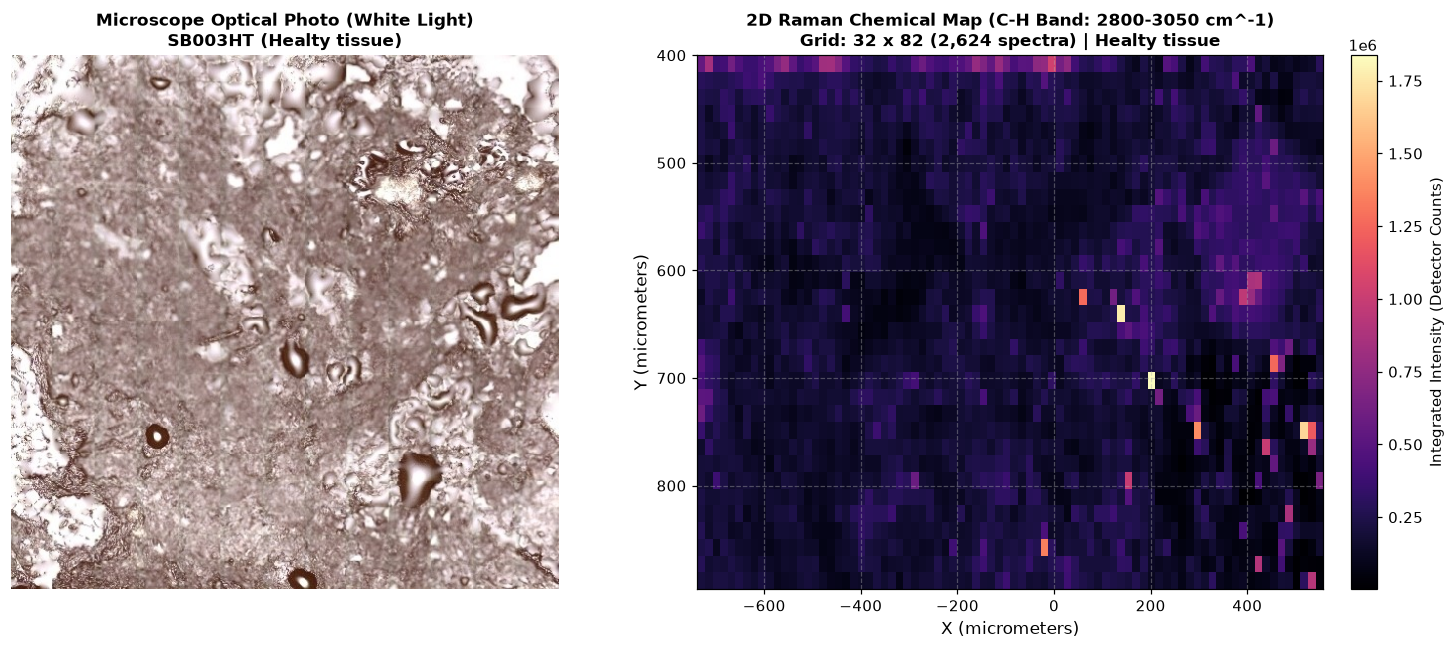

In [22]:
# Compute 2D integrated intensity map
# We integrate over the aliphatic C-H stretching band (2800 - 3050 cm^-1), which reflects cellular lipid/protein mass
ch_mask = (raman_shift >= 2800.0) & (raman_shift <= 3050.0)
if not np.any(ch_mask):
    ch_mask = np.ones_like(raman_shift, dtype=bool)

map_2d = np.nansum(intensity_cube[:, :, ch_mask], axis=-1)

# Display Optical Microscope Photo (if present in H5) alongside the 2D Raman Chemical Map
if has_optical_photo and optical_photo is not None:
    fig, (ax_opt, ax_map) = plt.subplots(1, 2, figsize=(14, 6))
    ax_opt.imshow(optical_photo)
    ax_opt.set_title(f'Microscope Optical Photo (White Light)\n{sample_id} ({tissue_label})', fontsize=11, fontweight='bold')
    ax_opt.axis('off')
else:
    fig, ax_map = plt.subplots(1, 1, figsize=(7.5, 6))

extent = None
if len(x_coords) == nx and len(y_coords) == ny:
    extent = [x_coords.min(), x_coords.max(), y_coords.max(), y_coords.min()]

im = ax_map.imshow(map_2d, cmap='magma', aspect='auto', extent=extent)
cbar = fig.colorbar(im, ax=ax_map, fraction=0.046, pad=0.04)
cbar.set_label('Integrated Intensity (Detector Counts)', fontsize=10)

units_lbl = f'({spatial_units})' if spatial_units else '(pixels)'
ax_map.set_xlabel(f'X {units_lbl}', fontsize=11)
ax_map.set_ylabel(f'Y {units_lbl}', fontsize=11)
ax_map.set_title(f'2D Raman Chemical Map (C-H Band: 2800-3050 cm^-1)\nGrid: {ny} x {nx} ({n_spectra:,} spectra) | {tissue_label}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Individual Pixel Spectra across the Full High-Wavenumber (HW) Region
We extract individual spectra from specific coordinates across the map and display them across the **entire acquired High-Wavenumber range**:
- **Full HW range**: Shows the raw spectrum from the lower boundary (~2480-2600 cm⁻¹) to the upper boundary (3300-4000 cm⁻¹).
- **Silent region (<2800 cm⁻¹)**: Evaluates background fluorescence and detector baseline.
- **C-H stretch region (2800–3050 cm⁻¹)**: Highlights the lipid and protein vibration bands ($2850\text{ CH}_2$, $2880\text{ CH}_2$, $2935\text{ CH}_3$, $2960\text{ CH}_3\text{ cm}^{-1}$).
- **O-H stretch region (>3100 cm⁻¹)**: Water and hydrogen-bonding band (prominent in hydrated samples).

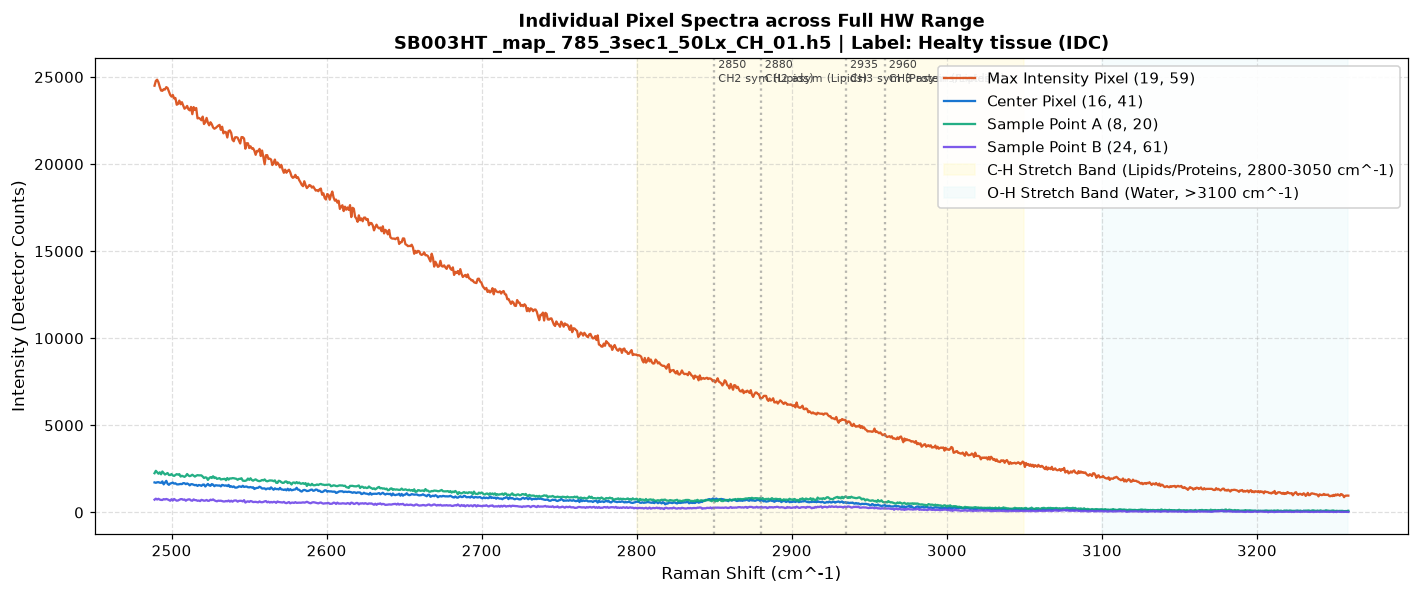

In [23]:
# Select representative pixel coordinates across the map
flat_intens = map_2d.flatten()
max_idx = int(np.nanargmax(flat_intens))
y_max, x_max = divmod(max_idx, nx)

y_center, x_center = ny // 2, nx // 2
y_pt1, x_pt1 = ny // 4, nx // 4
y_pt2, x_pt2 = (3 * ny) // 4, (3 * nx) // 4

pixels_to_plot = [
    (y_max, x_max, f'Max Intensity Pixel ({y_max}, {x_max})', '#d9480f'),
    (y_center, x_center, f'Center Pixel ({y_center}, {x_center})', '#0066cc'),
    (y_pt1, x_pt1, f'Sample Point A ({y_pt1}, {x_pt1})', '#0ca678'),
    (y_pt2, x_pt2, f'Sample Point B ({y_pt2}, {x_pt2})', '#7048e8'),
]

plt.figure(figsize=(13, 5.5))

for py, px, label_name, color_hex in pixels_to_plot:
    if py < ny and px < nx:
        single_spectrum = intensity_cube[py, px, :]
        plt.plot(raman_shift, single_spectrum, label=label_name, color=color_hex, lw=1.5, alpha=0.9)

# Highlight full HW sub-regions
plt.axvspan(2800, 3050, color='#fff9c4', alpha=0.35, label='C-H Stretch Band (Lipids/Proteins, 2800-3050 cm^-1)')

if raman_shift.max() >= 3150:
    plt.axvspan(3100, min(3650, raman_shift.max()), color='#e0f7fa', alpha=0.3, label='O-H Stretch Band (Water, >3100 cm^-1)')

# Annotate key C-H vibration markers
ch_markers = [
    (2850, 'CH2 sym (Lipids)'),
    (2880, 'CH2 asym (Lipids)'),
    (2935, 'CH3 sym (Proteins/Lipids)'),
    (2960, 'CH3 asym (Proteins)')
]
for peak_wn, peak_name in ch_markers:
    if raman_shift.min() <= peak_wn <= raman_shift.max():
        plt.axvline(peak_wn, color='#888888', linestyle=':', alpha=0.6)
        plt.text(peak_wn, plt.ylim()[1], f' {peak_wn}\n {peak_name}', fontsize=7.5, color='#444444', va='top')

plt.xlabel('Raman Shift (cm^-1)', fontsize=11)
plt.ylabel('Intensity (Detector Counts)', fontsize=11)
plt.title(f'Individual Pixel Spectra across Full HW Range\n{map_filepath.name} | Label: {tissue_label} ({histology})', fontsize=12, fontweight='bold')
plt.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

## 6. Multi-Spectra Overlay, Mean Spectrum, and Spectral Variance across Full HW
- **Background Cloud**: Sample of individual spectra across the tissue slice.
- **Mean Spectrum**: Global average profile across all $Ny \times Nx$ spectra.
- **Shaded Band**: $\pm 1$ Standard Deviation.
- **Lower Subplot**: Spectral Variance ($\sigma^2$) across all wavenumbers, highlighting where the sample varies the most.

[OK] Figure successfully saved to: C:\Users\alexf\Desktop\SPECTRA-BREAST\outputs\figures\hw_profile_SB003HT__map__785_3sec1_50Lx_CH_01.png


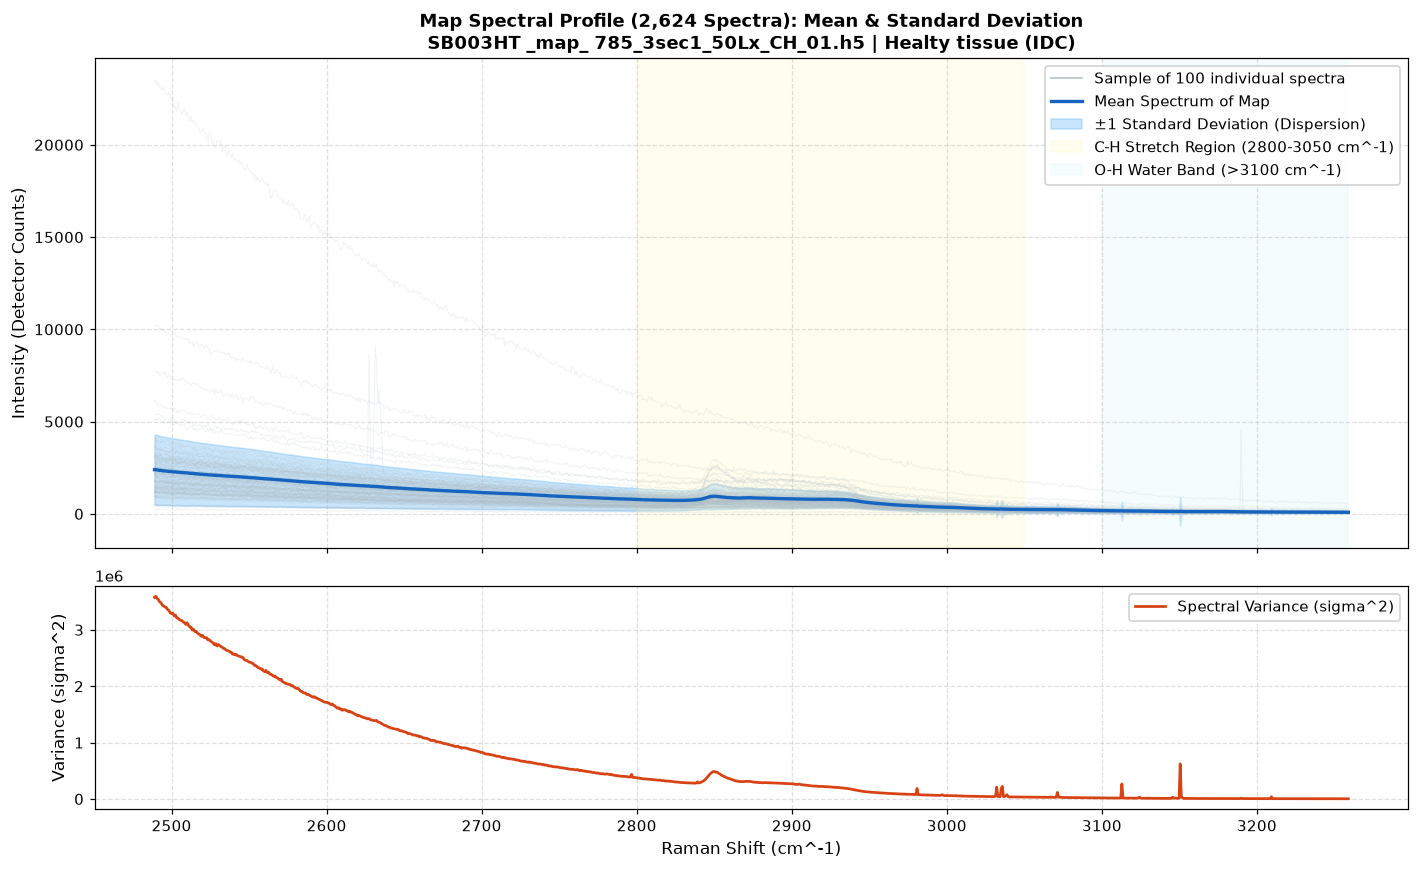

[OK] Analysis completed for: SB003HT _map_ 785_3sec1_50Lx_CH_01.h5
     - Label:            Healty tissue (IDC)
     - Global Mean:      800.56
     - Peak Intensity:   40183.75
     - Maximum Variance: 3595929.58 (at 2489.8 cm^-1)


In [24]:
# Flatten 3D cube into 2D matrix: (Total Spectra, Wavenumbers)
spectra_matrix = intensity_cube.reshape(-1, n_wn)

# Compute mean, standard deviation, and variance across all pixels
mean_spectrum = np.nanmean(spectra_matrix, axis=0)
std_spectrum = np.nanstd(spectra_matrix, axis=0)
variance_spectrum = np.nanvar(spectra_matrix, axis=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})

# 1. Overlay a sample of individual spectra in background
sample_count = min(100, spectra_matrix.shape[0])
sample_indices = np.random.choice(spectra_matrix.shape[0], size=sample_count, replace=False)

for idx in sample_indices:
    ax1.plot(raman_shift, spectra_matrix[idx, :], color='#b0bec5', alpha=0.18, lw=0.7)

ax1.plot([], [], color='#90a4ae', alpha=0.6, lw=1.2, label=f'Sample of {sample_count} individual spectra')

# Mean and standard deviation band
ax1.plot(raman_shift, mean_spectrum, color='#1565c0', lw=2.2, label='Mean Spectrum of Map')
ax1.fill_between(raman_shift, mean_spectrum - std_spectrum, mean_spectrum + std_spectrum,
                 color='#64b5f6', alpha=0.35, label='±1 Standard Deviation (Dispersion)')

ax1.axvspan(2800, 3050, color='#fff9c4', alpha=0.3, label='C-H Stretch Region (2800-3050 cm^-1)')
if raman_shift.max() >= 3150:
    ax1.axvspan(3100, min(3650, raman_shift.max()), color='#e0f7fa', alpha=0.3, label='O-H Water Band (>3100 cm^-1)')

ax1.set_ylabel('Intensity (Detector Counts)', fontsize=11)
ax1.set_title(f'Map Spectral Profile ({n_spectra:,} Spectra): Mean & Standard Deviation\n{map_filepath.name} | {tissue_label} ({histology})', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right', framealpha=0.92)

# 2. Spectral variance subplot
ax2.plot(raman_shift, variance_spectrum, color='#d84315', lw=1.8, label='Spectral Variance (sigma^2)')
ax2.set_xlabel('Raman Shift (cm^-1)', fontsize=11)
ax2.set_ylabel('Variance (sigma^2)', fontsize=11)
ax2.legend(loc='upper right', framealpha=0.92)

plt.tight_layout()

# Save diagnostic figure to outputs/figures/
figures_dir = Path('../outputs/figures').resolve()
if not figures_dir.exists():
    figures_dir = Path('outputs/figures').resolve()
figures_dir.mkdir(parents=True, exist_ok=True)

clean_stem = map_filepath.stem.replace(' ', '_')
fig_output_path = figures_dir / f'hw_profile_{clean_stem}.png'
fig.savefig(fig_output_path, dpi=130, bbox_inches='tight')
print(f'[OK] Figure successfully saved to: {fig_output_path}')

plt.show()

print(f'[OK] Analysis completed for: {map_filepath.name}')
print(f'     - Label:            {tissue_label} ({histology})')
print(f'     - Global Mean:      {mean_spectrum.mean():.2f}')
print(f'     - Peak Intensity:   {raw_intensity.max():.2f}')
print(f'     - Maximum Variance: {variance_spectrum.max():.2f} (at {raman_shift[np.argmax(variance_spectrum)]:.1f} cm^-1)')